Usethe trained model to predict house prices for the test data.
Evaluate the performance of the model using:

Mean Squared Error (MSE)
R²(R-squared) score

Perform
- K-Fold Cross-Validation on the training dataset and calculate the
cross-validation scores and their mean.

- Display the regression coefficients and intercept of the trained
model.
- Predict the price of a new house based on the given feature values.
- Interpret the results and comment on the performance of the model based on the evaluation metrics and cross-validation scores.

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold, train_test_split
from sklearn.datasets import fetch_california_housing

from sklearn.metrics import mean_squared_error, r2_score, make_scorer
import matplotlib.pyplot as plt

In [ ]:
housing = fetch_california_housing()
x = housing.data
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

model = LinearRegression()
k_fold = KFold(n_splits=10, shuffle=True, random_state=42)

In [ ]:
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=k_fold, scoring={
        "r2": make_scorer(r2_score),
        "mse": make_scorer(mean_squared_error)
    },
    return_estimator=True
)


trained_models = cv_results["estimator"]
r2_scores = cv_results["test_r2"]
mse_scores = cv_results["test_mse"]

## **Observability of models**

In [ ]:
print("model\tr2\tmse")
i = 1
for model, r2, mse in zip(trained_models, r2_scores, mse_scores):
    print(f"mean {i}\t{r2:.2f}\t{mse:.2f}")
    i+=1
print()
print(f"mean\t{r2_scores.mean():.2f}\t{mse_scores.mean():.2f}")

model	r2	mse
mean 1	0.58	0.59
mean 2	0.60	0.52
mean 3	0.62	0.47
mean 4	0.59	0.54
mean 5	0.62	0.51
mean 6	0.58	0.57
mean 7	0.62	0.52
mean 8	0.61	0.54
mean 9	0.57	0.58
mean 10	0.63	0.49

mean	0.60	0.53


In [ ]:
print("############## coeffients and intercept of models###################")
for i in trained_models:
  print(f"Coeffients for all features: { [f'{k:.2f}' for k in i.coef_] }")
  print(f"Intercept: {i.intercept_:.2f}")
  print()

############## coeffients and intercept of models###################
Coeffients for all features: ['0.44', '0.01', '-0.12', '0.65', '-0.00', '-0.00', '-0.41', '-0.43']
Intercept: -36.22

Coeffients for all features: ['0.43', '0.01', '-0.11', '0.62', '-0.00', '-0.00', '-0.42', '-0.44']
Intercept: -37.05

Coeffients for all features: ['0.44', '0.01', '-0.12', '0.65', '-0.00', '-0.00', '-0.42', '-0.43']
Intercept: -36.81

Coeffients for all features: ['0.43', '0.01', '-0.11', '0.61', '-0.00', '-0.00', '-0.42', '-0.44']
Intercept: -37.28

Coeffients for all features: ['0.43', '0.01', '-0.11', '0.62', '-0.00', '-0.00', '-0.42', '-0.44']
Intercept: -37.04

Coeffients for all features: ['0.44', '0.01', '-0.12', '0.80', '-0.00', '-0.00', '-0.42', '-0.44']
Intercept: -37.54

Coeffients for all features: ['0.43', '0.01', '-0.11', '0.62', '-0.00', '-0.00', '-0.42', '-0.43']
Intercept: -36.51

Coeffients for all features: ['0.43', '0.01', '-0.11', '0.64', '-0.00', '-0.00', '-0.42', '-0.44']
Interc

## **Predicting using the trained models**

Best model error: 0.52
Worst model error: 0.52


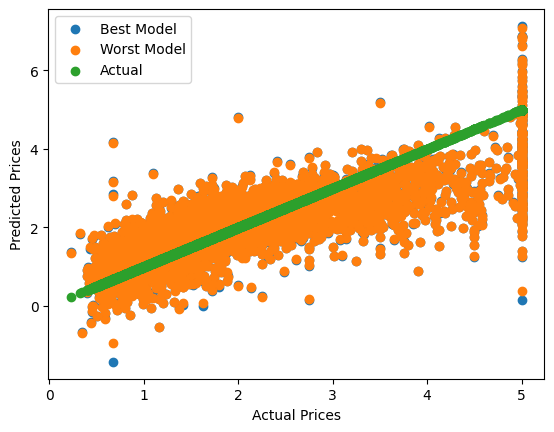

In [ ]:
# best model 8, worst model 4
best_model = trained_models[8]
worst_model = trained_models[4]

best_pred = best_model.predict(X_test)
best_pred_error = mean_squared_error(y_test, best_pred)

worst_pred = worst_model.predict(X_test)
worst_pred_error = mean_squared_error(y_test, worst_pred)

print(f"Best model error: {best_pred_error:.2f}")
print(f"Worst model error: {worst_pred_error:.2f}")


import matplotlib.pyplot as plt
plt.scatter(y_test, best_pred, label="Best Model")
plt.scatter(y_test, worst_pred, label="Worst Model")
plt.scatter(y_test, y_test, label="Actual")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.legend()
plt.show()

## **Interpretation:** Both best and worst model give almost similar results.